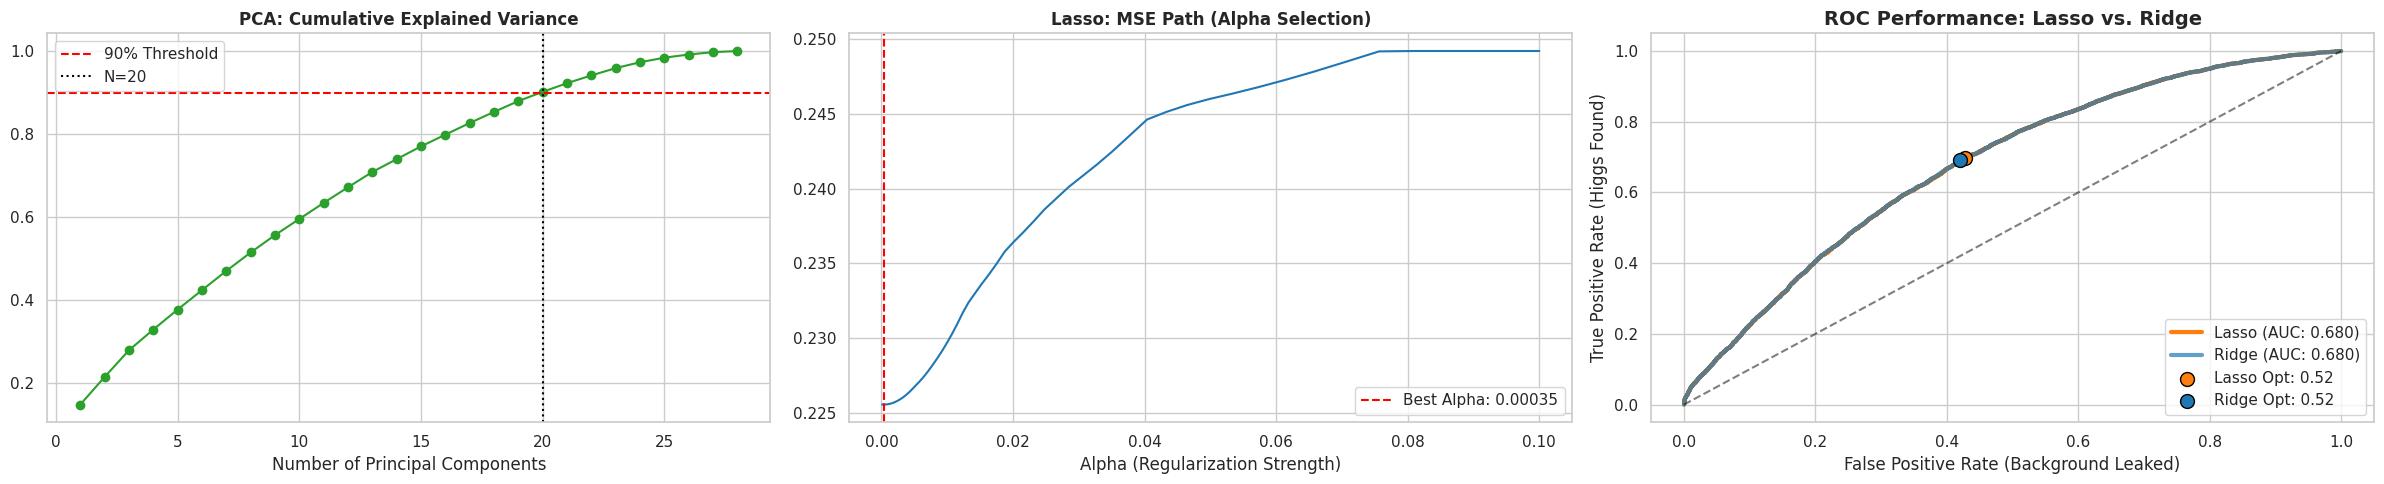

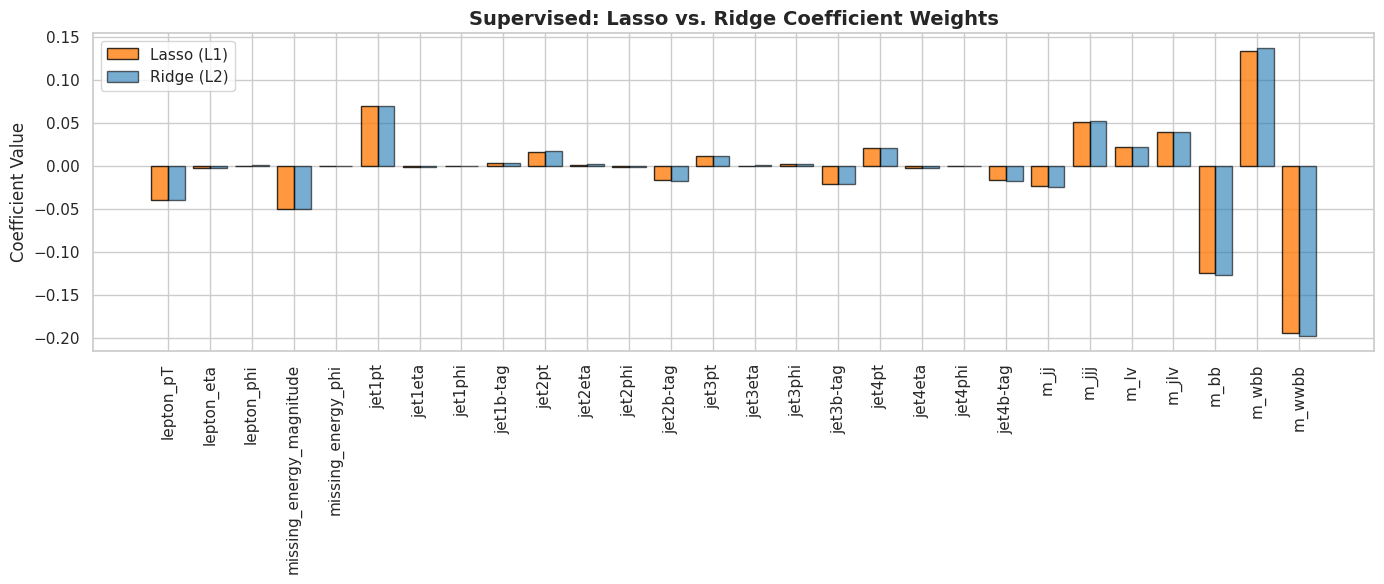

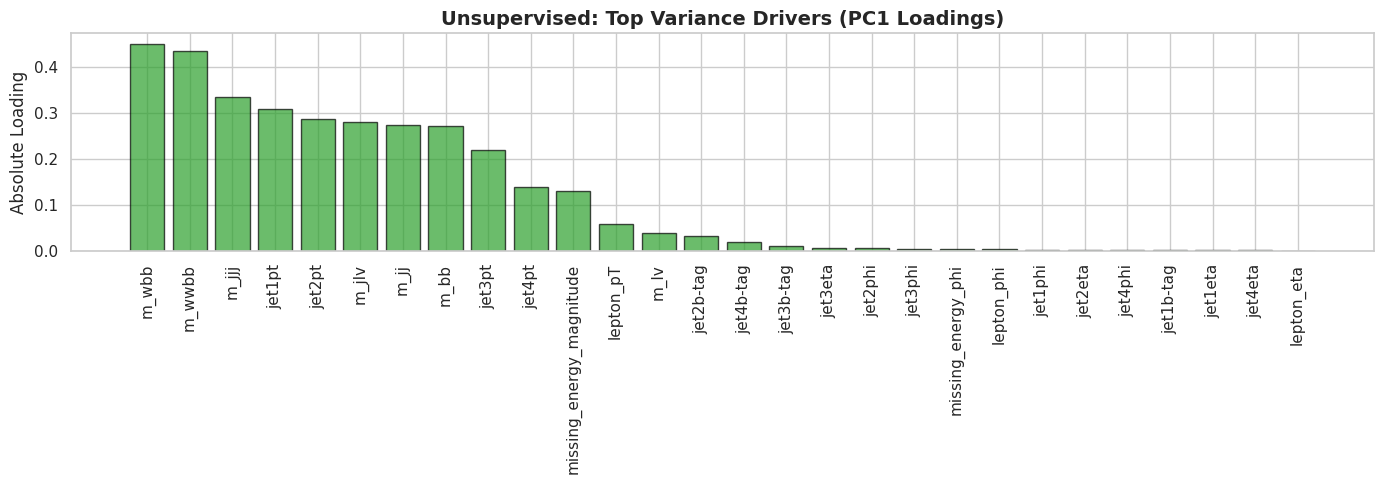

             FINAL EXOTIC HIGGS CLASSIFICATION REPORT
1. PERFORMANCE AT OPTIMAL THRESHOLD:
   - Lasso Accuracy: 63.84%
   - Ridge Accuracy: 63.81%
   - ROC AUC Lasso Score:  0.6802
   - ROC AUC Ridge Score:  0.6804

2. SPARSITY & FEATURE REDUNDANCY:
   - Lasso successfully eliminated 1 redundant variables.
   - Ridge retained all 28 variables, but reduced their influence.

3. THE PERFORMANCE CHANNEL (Top 3 Discriminators per Method):
   - PCA (Variance): m_wbb, m_wwbb, m_jjj
   - LASSO (Selection): m_wwbb, m_wbb, m_bb
   - RIDGE (Shrinkage): m_wwbb, m_wbb, m_bb

4. PCA INSIGHT:
   - Reduced complexity from 28 dimensions to 20 while keeping 90% variance.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.metrics import accuracy_score, roc_curve, auc
from sklearn.model_selection import KFold
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

# Load the Higgs dataset
higgs_data = fetch_openml (name='higgs', version=1, as_frame =True)
df = higgs_data .frame

# Set aesthetic theme
sns.set_theme(style="whitegrid")

# --- 1. DATA PREP & SCALING ---
# We fill NaNs with the mean to preserve as many collision events as possible
X = df.drop(columns=['class']).fillna(df.mean())
y = df['class'].astype(int)

# Scale data: Essential for PCA variance and L1/L2 penalty consistency
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
feature_names = X.columns

# Dividing in 80% training and 20% test
#The training is used for the extimation
#The test is used for the accuracy and ROC
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

# Nota: 'stratify=y' serve a mantenere la stessa proporzione di
# eventi Higgs/Background in entrambi i set.

# --- 2. AUTOMATIC CHOICE OF N (PCA) ---
pca_full = PCA().fit(X_train)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
# Select N to capture 90% of the statistical information
N_COMPONENTS = np.where(cumulative_variance >= 0.90)[0][0] + 1

pca = PCA(n_components=N_COMPONENTS)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# Unsupervised analysis: Which features drive the most variance?
#Selecting the [0] components, I'm chosing the first direction of spread of the datas
#The PCA rotates the df from the physics space of the columns to the
#Variance space and the components are the first, second ... directions
# in which the data are spread

loadings = pca.components_[0]
pca_analysis = pd.DataFrame({
    'Feature': feature_names,
    'Abs_Loading': np.abs(loadings)
}).sort_values('Abs_Loading', ascending=False)

#PC1 ([0]) captures the "Highways" of the data—the biggest trends.
#By the time you get to PC4 ([3]) for example, you are looking at the "Side Streets.
#"PC1: Usually explains 20 - 30 % of the total variance.
#PC4: Might only explain 3 - 5 %

# --- 3. SUPERVISED ANALYSIS: LASSO CV & RIDGE CV ---

# Define a range of alpha values to test
alphas_to_test = np.logspace(-4, -1, 100) # From 0.0001 to 1

# Initialize KFold cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

#find the best alpha

#Standard Ridge and Lasso classes
#need to manually set the alpha parameter
#instead of letting the model find the best one for you.+

#the problem here is the Lasso and Ridge MSE using. See the Giorgio exercise!!!

# Lasso (L1): Forces coefficients to zero (Feature Selection)
lasso_cv = LassoCV(alphas=alphas_to_test, cv=kf, max_iter=10000).fit(X_train, y_train)

# Ridge (L2): Shrinks coefficients toward zero (Noise Reduction)
ridge_cv = RidgeCV(alphas=alphas_to_test, cv=kf).fit(X_train, y_train)

#to find the best threshold for my data we use the roc curve

# --- 4. ROC CURVE ANALYSIS (FINDING THE THRESHOLD) ---


# --- ROC AUC INTERPRETATION ---
# 1. ROC (Receiver Operating Characteristic):
# A curve showing the relationship between two metrics as the decision threshold moves from 0 to 1:
# - True Positive Rate (TPR / Sensitivity): The ability to correctly identify real Higgs events.
# - False Positive Rate (FPR / 1-Specificity): The frequency of mistaking background noise for a Higgs boson.

# 2. AUC (Area Under the Curve):
# AUC represents the entire two-dimensional area underneath the ROC curve.
# It ranges from 0.5 to 1.0:
# - AUC = 1.0: Perfect model. It perfectly separates every Higgs event from the background.
# - AUC = 0.5: Useless model. Equivalent to a random coin flip (no predictive power).
# - 0.7 - 0.8: Good model.
# - 0.8 - 0.9: Excellent model (standard for well-trained Higgs classifiers).

# --- 4. ROC CURVE ANALYSIS (COMPARING LASSO & RIDGE) ---
# Get continuous scores for both

# Previsioni sui dati MAI visti (X_test)
lasso_scores = lasso_cv.predict(X_test)
ridge_scores = ridge_cv.predict(X_test)

# Calculate ROC components for Lasso
fpr_l, tpr_l, thresh_l = roc_curve(y_test, lasso_scores)
auc_lasso = auc(fpr_l, tpr_l)

# Calculate ROC components for Ridge
fpr_r, tpr_r, thresh_r = roc_curve(y_test, ridge_scores)
auc_ridge = auc(fpr_r, tpr_r)

# Find optimal thresholds using Youden's J statistic for both
idx_l = np.argmax(tpr_l - fpr_l)
opt_thresh_lasso = thresh_l[idx_l]

idx_r = np.argmax(tpr_r - fpr_r)
opt_thresh_ridge = thresh_r[idx_r]

# --- 5. ACCURACY MEASUREMENT (USING EACH MODEL'S BEST THRESHOLD) ---

lasso_preds = (lasso_scores > opt_thresh_lasso).astype(int)
ridge_preds = (ridge_scores > opt_thresh_ridge).astype(int)

lasso_acc = accuracy_score(y_test, lasso_preds)
ridge_acc = accuracy_score(y_test, ridge_preds)

# --- 5. IMPROVED VISUALIZATION ---

# FIGURE 1: Parameter Selection (N and Alpha)
fig, ax = plt.subplots(1, 3, figsize=(24, 5))

# PCA Elbow
ax[0].plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', color='#2ca02c')
ax[0].axhline(y=0.9, color='red', linestyle='--', label='90% Threshold')
ax[0].axvline(x=N_COMPONENTS, color='black', linestyle=':', label=f'N={N_COMPONENTS}')
ax[0].set_title("PCA: Cumulative Explained Variance", fontweight='bold')
ax[0].set_xlabel("Number of Principal Components")
ax[0].legend()

# Lasso Path
ax[1].plot(lasso_cv.alphas_, lasso_cv.mse_path_.mean(axis=-1), color='#1f77b4')
ax[1].axvline(x=lasso_cv.alpha_, color='red', linestyle='--', label=f'Best Alpha: {lasso_cv.alpha_:.5f}')
#ax[1].set_yscale('log')
ax[1].set_title("Lasso: MSE Path (Alpha Selection)", fontweight='bold')
ax[1].set_xlabel("Alpha (Regularization Strength)")
ax[1].legend()

# THE ROC COMPARISON DUEL
# Lasso Curve
ax[2].plot(fpr_l, tpr_l, color='#ff7f0e', lw=3, label=f'Lasso (AUC: {auc_lasso:.3f})')
# Ridge Curve
ax[2].plot(fpr_r, tpr_r, color='#1f77b4', lw=3, label=f'Ridge (AUC: {auc_ridge:.3f})', alpha=0.7)

# Diagonal Random-Chance Line
ax[2].plot([0, 1], [0, 1], color='black', linestyle='--', alpha=0.5)

# Marking the Optimal Threshold points found via Youden's J
ax[2].scatter(fpr_l[idx_l], tpr_l[idx_l], color='#ff7f0e', s=100, edgecolors='black',
              zorder=5, label=f'Lasso Opt: {opt_thresh_lasso:.2f}')
ax[2].scatter(fpr_r[idx_r], tpr_r[idx_r], color='#1f77b4', s=100, edgecolors='black',
              zorder=5, label=f'Ridge Opt: {opt_thresh_ridge:.2f}')

ax[2].set_title("ROC Performance: Lasso vs. Ridge", fontweight='bold', fontsize=14)
ax[2].set_xlabel("False Positive Rate (Background Leaked)")
ax[2].set_ylabel("True Positive Rate (Higgs Found)")
ax[2].legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

# FIGURE 2: REGULARIZATION DUEL (Lasso vs Ridge)
fig, ax = plt.subplots(figsize=(14, 6))
x_axis = np.arange(len(feature_names))

ax.bar(x_axis - 0.2, lasso_cv.coef_, width=0.4, label='Lasso (L1)', color='#ff7f0e', alpha=0.8, edgecolor='black')
ax.bar(x_axis + 0.2, ridge_cv.coef_, width=0.4, label='Ridge (L2)', color='#1f77b4', alpha=0.6, edgecolor='black')

ax.set_xticks(x_axis)
ax.set_xticklabels(feature_names, rotation=90)
ax.set_title("Supervised: Lasso vs. Ridge Coefficient Weights", fontsize=14, fontweight='bold')
ax.set_ylabel("Coefficient Value")
ax.legend()
plt.tight_layout()
plt.show()

# FIGURE 3: PCA LOADINGS (The Unsupervised View)
plt.figure(figsize=(14, 5))
plt.bar(pca_analysis['Feature'], pca_analysis['Abs_Loading'], color='#2ca02c', alpha=0.7, edgecolor='black')
plt.title("Unsupervised: Top Variance Drivers (PC1 Loadings)", fontsize=14, fontweight='bold')
plt.ylabel("Absolute Loading")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# --- 6. SPECIFIC PHYSICS CONCLUSIONS ---
print("="*60)
print("             FINAL EXOTIC HIGGS CLASSIFICATION REPORT")
print("="*60)
print(f"1. PERFORMANCE AT OPTIMAL THRESHOLD:")
print(f"   - Lasso Accuracy: {lasso_acc:.2%}")
print(f"   - Ridge Accuracy: {ridge_acc:.2%}")
print(f"   - ROC AUC Lasso Score:  {auc_lasso:.4f}")
print(f"   - ROC AUC Ridge Score:  {auc_ridge:.4f}")

print(f"\n2. SPARSITY & FEATURE REDUNDANCY:")
n_zero = np.sum(lasso_cv.coef_ == 0)
print(f"   - Lasso successfully eliminated {n_zero} redundant variables.")
print(f"   - Ridge retained all {len(feature_names)} variables, but reduced their influence.")

print(f"\n3. THE PERFORMANCE CHANNEL (Top 3 Discriminators per Method):")

# 1. Top features for PCA (Unsupervised - Variance)
top_pca = pd.DataFrame({'F': feature_names, 'C': np.abs(pca.components_[0])}).sort_values('C', ascending=False)

# 2. Top features for LASSO (Supervised - L1 Selection)
top_lasso = pd.DataFrame({'F': feature_names, 'C': np.abs(lasso_cv.coef_)}).sort_values('C', ascending=False)

# 3. Top features for RIDGE (Supervised - L2 Selection)
top_ridge = pd.DataFrame({'F': feature_names, 'C': np.abs(ridge_cv.coef_)}).sort_values('C', ascending=False)

# Stampa dei risultati
print(f"   - PCA (Variance): {', '.join(top_pca['F'].iloc[:3].tolist())}")
print(f"   - LASSO (Selection): {', '.join(top_lasso['F'].iloc[:3].tolist())}")
print(f"   - RIDGE (Shrinkage): {', '.join(top_ridge['F'].iloc[:3].tolist())}")

print(f"\n4. PCA INSIGHT:")
print(f"   - Reduced complexity from {len(feature_names)} dimensions to {N_COMPONENTS} while keeping 90% variance.")
print("="*60)
